# B0, B1 i warianty przetwarzania P1-P3 (Milestone 2)

Plan:
1. zamrożony podział z Milestone 1 (te same rekordy testowe dla wszystkich wariantów),
2. B0: klasa większościowa; B0r: prosta reguła ze znaczników z EDA; B1: surowy tekst → TF-IDF → regresja logistyczna,
3. warianty P1-P3 przy **tym samym** wektoryzatorze i tym samym `C`, najpierw pojedynczo, potem połączenie,
4. wyniki na teście, przedział ufności różnicy B1 vs wariant wybrany na walidacji (bootstrap sparowany),
5. podzbiory testu (bez duplikatów, bez podobnych kampanii) i test odporności na literówki.

Na walidacji wybieramy: `C` dla B1, próg decyzji każdego wariantu i wariant końcowy. Test służy tylko do raportowania.

Ustawienia: `configs/experiments.toml`. Notebook zapisuje predykcje i tabele do `results/` oraz wykres do `reports/milestone2/`.

Uruchomienie: `uv run jupyter nbconvert --to notebook --execute --inplace notebooks/02_baselines.ipynb`

## 0. Konfiguracja

In [1]:
import json
import platform
import subprocess
import time
import tomllib
from importlib.metadata import version

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from smsspam import evaluate as ev
from smsspam import preprocess as pp
from smsspam.data import ROOT, load_config, load_split
from smsspam.rules import RULE_MARKERS, marker_count
from smsspam.typos import add_typos

with open(ROOT / "configs" / "experiments.toml", "rb") as f:
    exp = tomllib.load(f)
data_cfg = load_config()
RESULTS = ROOT / "results"
FIGS = ROOT / "reports" / "milestone2"
RESULTS.mkdir(exist_ok=True)
FIGS.mkdir(parents=True, exist_ok=True)
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
SPAM = "#eb6834"
pd.set_option("display.max_colwidth", 160)
pd.set_option("display.precision", 4)

## 1. Dane i podział

`load_split()` wczytuje surowy plik i sprawdza, że teksty zgadzają się z zamrożonym podziałem (SHA-1 każdego rekordu).

In [2]:
df = load_split(data_cfg["split"]["seed"])
df["y"] = (df.label == "spam").astype(int)
parts = {s: df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test")}
df.groupby(["split", "label"]).size().unstack()

label,ham,spam
split,,
test,724,113
train,3378,522
val,725,112


Dla podzbiorów testu potrzebujemy największego podobieństwa każdego rekordu testowego do treningu.
Liczymy je tak samo jak przy kontroli podziału w Milestone 1 (TF-IDF n-gramów znakowych 3-5, bez etykiet).
To narzędzie kontroli podziału, nie cecha modelu.

In [3]:
nd = data_cfg["near_dup"]
char_vec = TfidfVectorizer(analyzer=nd["analyzer"], ngram_range=(nd["ngram_min"], nd["ngram_max"]),
                           sublinear_tf=True).fit(df.text)
test = parts["test"]
test["max_sim_to_train"] = (char_vec.transform(test.text) @ char_vec.transform(parts["train"].text).T).max(axis=1).toarray().ravel()
test["first_copy"] = ~test.text.duplicated()
print("test:", len(test), "| unikalne teksty:", test.first_copy.sum(),
      "| podobieństwo do train >= 0.5:", (test.max_sim_to_train >= 0.5).sum())

test: 837 | unikalne teksty: 781 | podobieństwo do train >= 0.5: 120


## 2. B0: klasa większościowa

Zawsze `ham`. F1 spamu = 0, a PR-AUC stałego wyniku równa się udziałowi spamu.

In [4]:
rows = []
for s in ("val", "test"):
    p = parts[s]
    rows.append({"część": s, **ev.metrics(p.y.to_numpy(), np.zeros(len(p)), threshold=0.5)})
b0 = pd.DataFrame(rows).set_index("część")
b0

,f1_spam,precision_spam,recall_spam,macro_f1,pr_auc,FP,FN
część,,,,,,,
val,0.0,0.0,0.0,0.4641,0.1338,0,112
test,0.0,0.0,0.0,0.4638,0.1350,0,113


## 2b. B0r: reguła ze znaczników

B0 nic nie wykrywa, więc dodajemy mocniejszy punkt odniesienia bez uczenia: reguła z czterech znaczników,
które w EDA najsilniej odróżniały spam (numer telefonu, kwota, kod krótki, URL; `smsspam/rules.py`).
Wynik reguły to liczba znaczników w wiadomości (0-4). Wiadomość jest spamem, gdy ma co najmniej `k` znaczników.
`k` wybieramy na walidacji (maks. F1 spamu). Wzorce powstały na podstawie treningu w Milestone 1.

In [5]:
for p in parts.values():
    p["markers"] = p.text.map(marker_count)
print("znaczniki:", list(RULE_MARKERS))
display(parts["train"].groupby("markers").y.agg(wiadomości="size", udział_spamu="mean").T)

rule_val = pd.DataFrame([{"k": k, **ev.metrics(parts["val"].y.to_numpy(), parts["val"].markers.to_numpy(), k)}
                         for k in range(1, 5)]).set_index("k")
K_RULE = int(rule_val.f1_spam.idxmax())
print("wybrane k =", K_RULE)
rule_val

znaczniki: ['phone', 'money', 'shortcode', 'url']


markers,0,1,2,3,4
wiadomości,3400.0000,191.0000,242.0,55.0,12.0
udział_spamu,0.0135,0.8743,1.0,1.0,1.0


wybrane k = 1


,f1_spam,precision_spam,recall_spam,macro_f1,pr_auc,FP,FN
k,,,,,,,
1,0.9048,0.9694,0.8482,0.9456,0.8584,3,17
2,0.6824,1.0000,0.5179,0.8232,0.8584,0,54
3,0.2636,1.0000,0.1518,0.6010,0.8584,0,95
4,0.0522,1.0000,0.0268,0.4911,0.8584,0,109


In [6]:
b0r = pd.DataFrame([{"część": s, **ev.metrics(parts[s].y.to_numpy(), parts[s].markers.to_numpy(), K_RULE)}
                    for s in ("val", "test")]).set_index("część")
b0r

,f1_spam,precision_spam,recall_spam,macro_f1,pr_auc,FP,FN
część,,,,,,,
val,0.9048,0.9694,0.8482,0.9456,0.8584,3,17
test,0.9364,0.9626,0.9115,0.9634,0.9152,4,10


## 3. B1: surowy tekst → TF-IDF → regresja logistyczna

Tekst bez żadnego czyszczenia. Tokenizacja i normalizacja są jawne w `configs/experiments.toml`:
małe litery, domyślny `token_pattern` (tokeny ≥ 2 znaków alfanumerycznych, interpunkcja pomijana), unigramy, normalizacja L2.
TF-IDF dopasowujemy tylko do treningu.

`C` wybieramy na walidacji po PR-AUC (miara niezależna od progu; F1 przy 112 spamach w walidacji mocno skacze).
Próg decyzji: maksymalne F1 spamu na walidacji.

In [7]:
tf = exp["b1"]["tfidf"]
lr = exp["b1"]["logreg"]
VEC_PARAMS = {**tf, "ngram_range": tuple(tf["ngram_range"])}


def lr_params(C):
    return {"C": C, "solver": lr["solver"], "l1_ratio": lr["l1_ratio"], "max_iter": lr["max_iter"],
            "class_weight": None if lr["class_weight"] == "none" else lr["class_weight"], "random_state": 42}


def fit_predict(transform, C, splits=("val", "test"), texts=None):
    # Fit TF-IDF + LR on transformed train text; return scores (P(spam)) for the requested parts.
    t0 = time.perf_counter()
    vec = TfidfVectorizer(**VEC_PARAMS)
    X = vec.fit_transform(parts["train"].text.map(transform))
    model = LogisticRegression(**lr_params(C)).fit(X, parts["train"].y)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    scores = {s: model.predict_proba(vec.transform((texts or {}).get(s, parts[s].text).map(transform)))[:, 1]
              for s in splits}
    return scores, {"fit_s": fit_s, "predict_s": time.perf_counter() - t0, "n_features": X.shape[1]}


y_val, y_test = parts["val"].y.to_numpy(), parts["test"].y.to_numpy()
grid = []
for C in lr["C_grid"]:
    s, _ = fit_predict(pp.identity, C, splits=("val",))
    th = ev.best_threshold(y_val, s["val"])
    grid.append({"C": C, "próg": th, **ev.metrics(y_val, s["val"], th)})
grid = pd.DataFrame(grid).set_index("C")
C_B1 = float(grid.pr_auc.idxmax())  # idxmax takes the first maximum, i.e. the smaller C on ties
print("wybrane C =", C_B1)
grid

wybrane C = 300.0


,próg,f1_spam,precision_spam,recall_spam,macro_f1,pr_auc,FP,FN
C,,,,,,,,
0.1,0.1925,0.8789,0.8829,0.8750,0.9302,0.9355,13,14
0.3,0.2411,0.8950,0.9159,0.8750,0.9396,0.9469,9,14
1.0,0.2863,0.9083,0.9340,0.8839,0.9473,0.9550,7,13
3.0,0.2133,0.9156,0.9115,0.9196,0.9512,0.9579,10,9
10.0,0.4434,0.9167,0.9519,0.8839,0.9522,0.9603,5,13
30.0,0.1954,0.9156,0.9115,0.9196,0.9512,0.9611,10,9
100.0,0.2315,0.9148,0.9189,0.9107,0.9509,0.9607,9,10
300.0,0.3614,0.9224,0.9439,0.9018,0.9553,0.9619,6,11
1000.0,0.3643,0.9224,0.9439,0.9018,0.9553,0.9612,6,11


## 4. Warianty P na walidacji

Ten sam wektoryzator i to samo `C` co w B1; zmienia się tylko tekst wejściowy (`smsspam/preprocess.py`).
Próg decyzji dobieramy osobno dla każdego wariantu, tylko na walidacji, bo maskowanie przesuwa rozkład wyników.
Kolumna „F1 @ próg B1” pokazuje wynik przy progu B1, żeby było widać, ile daje sam próg.

- **P1**: kwoty, numery telefonów i kody krótkie → `_money_`, `_phone_`, `_shortcode_`,
- **P2a**: URL → `_url_`; **P2b**: URL usunięty,
- **P3**: ≥ 3 powtórzone litery lub `! ? .` → 2.

In [8]:
scores, cost, thresholds = {}, {}, {}


def run(name, transform):
    scores[name], cost[name] = fit_predict(transform, C_B1)
    thresholds[name] = ev.best_threshold(y_val, scores[name]["val"])


for name, transform in pp.VARIANTS.items():
    run(name, transform)


def val_table(names):
    out = []
    for n in names:
        m = ev.metrics(y_val, scores[n]["val"], thresholds[n])
        out.append({"wariant": n, "próg": thresholds[n], **m,
                    "F1 @ próg B1": ev.metrics(y_val, scores[n]["val"], thresholds["B1"])["f1_spam"],
                    "cechy": cost[n]["n_features"]})
    return pd.DataFrame(out).set_index("wariant")


val_single = val_table(pp.VARIANTS)
val_single

,próg,f1_spam,precision_spam,recall_spam,macro_f1,pr_auc,FP,FN,F1 @ próg B1,cechy
wariant,,,,,,,,,,
B1,0.3614,0.9224,0.9439,0.9018,0.9553,0.9619,6,11,0.9224,7171
P1,0.4482,0.9585,0.9905,0.9286,0.9762,0.9737,1,8,0.9541,6803
P2a,0.3756,0.9259,0.9615,0.8929,0.9575,0.9630,4,12,0.9259,7109
P2b,0.4852,0.9057,0.9600,0.8571,0.9460,0.9569,4,16,0.9000,7108
P3,0.3610,0.9224,0.9439,0.9018,0.9553,0.9629,6,11,0.9124,7146


### Połączenie wariantów

Łączymy warianty pojedyncze, które na walidacji nie pogorszyły ani F1, ani PR-AUC względem B1
(z P2 bierzemy lepszą wersję). Wariant końcowy to najwyższe F1 spamu na walidacji, przy remisie wyższe PR-AUC.

In [9]:
b1v = val_single.loc["B1"]
ok = [n for n in ("P1", "P2a", "P2b", "P3")
      if val_single.loc[n, "f1_spam"] >= b1v.f1_spam and val_single.loc[n, "pr_auc"] >= b1v.pr_auc]
p2 = [n for n in ok if n.startswith("P2")]
if len(p2) == 2:
    ok.remove(min(p2, key=lambda n: (val_single.loc[n, "f1_spam"], val_single.loc[n, "pr_auc"])))
order = {"P2a": 0, "P2b": 0, "P1": 1, "P3": 2}  # URLs first, so digits in links are not masked
ok = sorted(ok, key=order.get)
print("warianty bez pogorszenia na walidacji:", ok)

combos = {}
if len(ok) >= 2:
    from itertools import combinations
    for k in range(2, len(ok) + 1):
        for c in combinations(ok, k):
            combos["+".join(c)] = pp.compose(*(pp.VARIANTS[n] for n in c))
for name, transform in combos.items():
    run(name, transform)

val_all = val_table([*pp.VARIANTS, *combos])
candidates = val_all.drop(index="B1")
BEST = candidates.sort_values(["f1_spam", "pr_auc"], ascending=False).index[0]
print("wariant wybrany na walidacji:", BEST)
val_all

warianty bez pogorszenia na walidacji: ['P2a', 'P1', 'P3']


wariant wybrany na walidacji: P2a+P1+P3


,próg,f1_spam,precision_spam,recall_spam,macro_f1,pr_auc,FP,FN,F1 @ próg B1,cechy
wariant,,,,,,,,,,
B1,0.3614,0.9224,0.9439,0.9018,0.9553,0.9619,6,11,0.9224,7171
P1,0.4482,0.9585,0.9905,0.9286,0.9762,0.9737,1,8,0.9541,6803
P2a,0.3756,0.9259,0.9615,0.8929,0.9575,0.9630,4,12,0.9259,7109
P2b,0.4852,0.9057,0.9600,0.8571,0.9460,0.9569,4,16,0.9000,7108
P3,0.3610,0.9224,0.9439,0.9018,0.9553,0.9629,6,11,0.9124,7146
P2a+P1,0.4876,0.9677,1.0000,0.9375,0.9815,0.9750,0,7,0.9636,6744
P2a+P3,0.3762,0.9259,0.9615,0.8929,0.9575,0.9640,4,12,0.9259,7084
P1+P3,0.4513,0.9585,0.9905,0.9286,0.9762,0.9738,1,8,0.9541,6778
P2a+P1+P3,0.4914,0.9677,1.0000,0.9375,0.9815,0.9751,0,7,0.9636,6719


## 5. Test: wszystkie warianty na tych samych 837 rekordach

Progi i `C` są zamrożone z walidacji. FP to ham oznaczony jako spam (fałszywy alarm), FN to niewykryty spam.

In [10]:
NAMES = list(val_all.index)
test_rows = [{"wariant": "B0", **ev.metrics(y_test, np.zeros(len(y_test)), 0.5)},
             {"wariant": "B0r", **ev.metrics(y_test, test.markers.to_numpy(), K_RULE)}]
for n in NAMES:
    test_rows.append({"wariant": n, **ev.metrics(y_test, scores[n]["test"], thresholds[n])})
test_table = pd.DataFrame(test_rows).set_index("wariant")
test_table

,f1_spam,precision_spam,recall_spam,macro_f1,pr_auc,FP,FN
wariant,,,,,,,
B0,0.0000,0.0000,0.0000,0.4638,0.1350,0,113
B0r,0.9364,0.9626,0.9115,0.9634,0.9152,4,10
B1,0.9395,0.9902,0.8938,0.9653,0.9802,1,12
P1,0.9589,0.9906,0.9292,0.9764,0.9821,1,8
P2a,0.9444,0.9903,0.9027,0.9681,0.9799,1,11
P2b,0.9194,0.9898,0.8584,0.9539,0.9799,1,16
P3,0.9395,0.9902,0.8938,0.9653,0.9808,1,12
P2a+P1,0.9537,1.0000,0.9115,0.9734,0.9818,0,10
P2a+P3,0.9444,0.9903,0.9027,0.9681,0.9800,1,11


## 6. Niepewność: bootstrap sparowany B1 vs warianty

2000 losowań ze zwracaniem tych samych rekordów testowych dla obu modeli; 95% przedział percentylowy różnicy F1 spamu.
Druga wersja losuje całe grupy bliskich duplikatów (kopie jednej kampanii nie są niezależne), więc daje szerszy, uczciwszy przedział.
Rozstrzygające jest porównanie B1 z wariantem wybranym na walidacji; pozostałe wiersze są opisowe.

In [11]:
bs = exp["bootstrap"]
pred = {n: (scores[n]["test"] >= thresholds[n]).astype(int) for n in NAMES}
boot = []
for n in NAMES[1:]:
    r = ev.paired_bootstrap(y_test, pred["B1"], pred[n], n=bs["n"], seed=bs["seed"])
    g = ev.paired_bootstrap(y_test, pred["B1"], pred[n], n=bs["n"], seed=bs["seed"], groups=test.dup_group)
    boot.append({"wariant": n, "ΔF1": r["diff"], "CI 2.5%": r["ci_low"], "CI 97.5%": r["ci_high"],
                 "P(Δ ≤ 0)": r["p_le_0"], "CI grupy 2.5%": g["ci_low"], "CI grupy 97.5%": g["ci_high"],
                 "wybrany na val": n == BEST})
boot = pd.DataFrame(boot).set_index("wariant")
display(boot)

# Context: is B1 clearly better than the hand-written rule?
r = ev.paired_bootstrap(y_test, (test.markers >= K_RULE).astype(int), pred["B1"], n=bs["n"], seed=bs["seed"])
print(f"B1 - B0r: ΔF1 = {r['diff']:+.4f}, 95% CI [{r['ci_low']:+.4f}; {r['ci_high']:+.4f}]")

,ΔF1,CI 2.5%,CI 97.5%,P(Δ ≤ 0),CI grupy 2.5%,CI grupy 97.5%,wybrany na val
wariant,,,,,,,
P1,0.0194,-0.0102,0.0518,0.100,-0.0111,0.0531,False
P2a,0.0049,0.0000,0.0163,0.382,0.0000,0.0171,False
P2b,-0.0201,-0.0438,-0.0046,1.000,-0.0511,0.0000,False
P3,0.0000,0.0000,0.0000,1.000,0.0000,0.0000,False
P2a+P1,0.0142,-0.0101,0.0411,0.176,-0.0106,0.0408,False
P2a+P3,0.0049,0.0000,0.0163,0.382,0.0000,0.0171,False
P1+P3,0.0194,-0.0102,0.0518,0.100,-0.0111,0.0531,False
P2a+P1+P3,0.0142,-0.0101,0.0411,0.176,-0.0106,0.0408,True


B1 - B0r: ΔF1 = +0.0032, 95% CI [-0.0359; +0.0424]


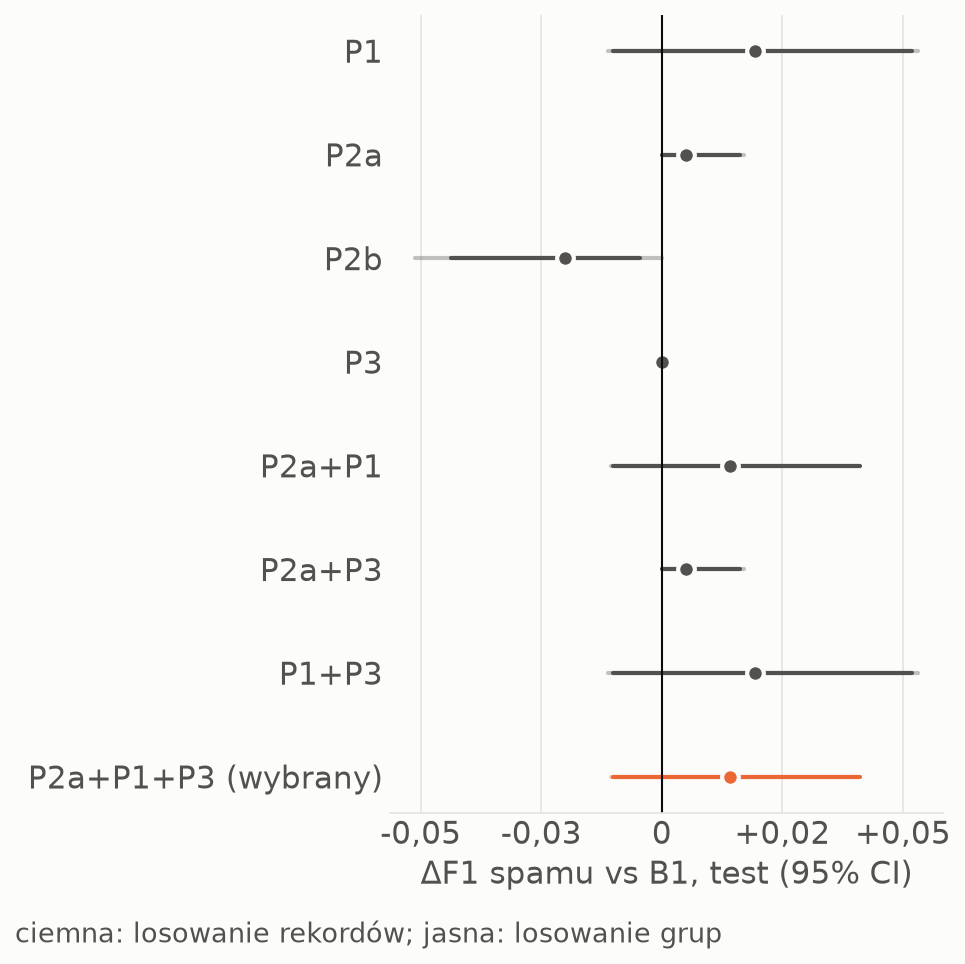

In [12]:
fig, ax = plt.subplots(figsize=(6.4, 0.6 * len(boot) + 1.6), dpi=150)
fig.patch.set_facecolor(SURFACE)
ax.set_facecolor(SURFACE)
yy = np.arange(len(boot))[::-1]
for yi, (n, r) in zip(yy, boot.iterrows()):
    color = SPAM if r["wybrany na val"] else INK_2
    ax.plot([r["CI grupy 2.5%"], r["CI grupy 97.5%"]], [yi, yi], color=color, lw=2, solid_capstyle="round", alpha=0.35)
    ax.plot([r["CI 2.5%"], r["CI 97.5%"]], [yi, yi], color=color, lw=2, solid_capstyle="round")
    ax.plot(r["ΔF1"], yi, "o", ms=8, color=color, mec=SURFACE, mew=2)
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(yy, [f"{n} (wybrany)" if r["wybrany na val"] else n for n, r in boot.iterrows()])
ax.set_xlabel("ΔF1 spamu vs B1, test (95% CI)", color=INK_2, fontsize=15)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
ax.tick_params(colors=INK_2, labelsize=15, length=0)
ax.grid(axis="x", color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:+.2f}".replace("+0.00", "0").replace(".", ","))
fig.text(0.01, 0.01, "ciemna: losowanie rekordów; jasna: losowanie grup",
         color=INK_2, fontsize=13)
fig.tight_layout(rect=(0, 0.04, 1, 1))
fig.savefig(FIGS / "fig_delta.png", facecolor=SURFACE)
plt.show()

## 7. Podzbiory testu

- **bez duplikatów**: pierwsza kopia każdego tekstu (powtarzane kampanie nie ważą wielokrotnie),
- **podobieństwo < 0,5**: bez wiadomości przypominających kampanie z treningu.

In [13]:
subsets = {"cały test": np.ones(len(test), bool), "bez duplikatów": test.first_copy.to_numpy(),
           "podobieństwo < 0,5": (test.max_sim_to_train < 0.5).to_numpy()}
sub_rows = []
for sname, mask in subsets.items():
    for n in ("B1", BEST):
        m = ev.metrics(y_test[mask], scores[n]["test"][mask], thresholds[n])
        sub_rows.append({"podzbiór": sname, "wariant": n, "rekordy": int(mask.sum()), "spam": int(y_test[mask].sum()),
                         **{k: m[k] for k in ("f1_spam", "precision_spam", "recall_spam", "pr_auc", "FP", "FN")}})
subset_table = pd.DataFrame(sub_rows).set_index(["podzbiór", "wariant"])
subset_table

rekordy  spam  f1_spam  precision_spam  \
podzbiór           wariant                                             
cały test          B1             837   113   0.9395          0.9902   
                   P2a+P1+P3      837   113   0.9537          1.0000   
bez duplikatów     B1             781   102   0.9381          0.9891   
                   P2a+P1+P3      781   102   0.9538          1.0000   
podobieństwo < 0,5 B1             717    72   0.9023          0.9836   
                   P2a+P1+P3      717    72   0.9254          1.0000   

                              recall_spam  pr_auc  FP  FN  
podzbiór           wariant                                 
cały test          B1              0.8938  0.9802   1  12  
                   P2a+P1+P3       0.9115  0.9815   0  10  
bez duplikatów     B1              0.8922  0.9778   1  11  
                   P2a+P1+P3       0.9118  0.9793   0   9  
podobieństwo < 0,5 B1              0.8333  0.9641   1  12  
                   P2a+P1+P3       0.8611  0.9664   0  10

## 8. Odporność na kontrolowane literówki

Każde słowo z ≥ 3 liter dostaje z prawdopodobieństwem `rate` jedną edycję (usunięcie, zamiana sąsiednich liter,
podmiana, podwojenie). Literówki dodajemy tylko do tekstów testu, przed przetwarzaniem wariantu; modele są te same
(trening na czystym tekście), progi z walidacji. Trzy ziarna literówek, podajemy średnią i odchylenie standardowe.

In [14]:
ty = exp["typos"]
robust_names = list(dict.fromkeys(["B1", "P3", BEST]))
robust = []
for rate in ty["rates"]:
    for seed in ty["seeds"]:
        noisy = test.apply(lambda r: add_typos(r.text, rate, seed, r.id), axis=1)
        for n in robust_names:
            transform = pp.VARIANTS.get(n) or combos[n]
            s, _ = fit_predict(transform, C_B1, splits=("test",), texts={"test": noisy})
            robust.append({"rate": rate, "seed": seed, "wariant": n,
                           **ev.metrics(y_test, s["test"], thresholds[n])})
robust = pd.DataFrame(robust)
clean = test_table.loc[robust_names, "f1_spam"].rename("F1 czysty")
robust_table = (robust.groupby(["wariant", "rate"]).f1_spam.agg(["mean", "std"]).unstack("rate"))
robust_table.columns = [f"F1 {stat} @ {rate}" for stat, rate in robust_table.columns]
robust_table = pd.concat([clean, robust_table], axis=1).loc[robust_names]
robust_table

,F1 czysty,F1 mean @ 0.1,F1 mean @ 0.2,F1 std @ 0.1,F1 std @ 0.2
wariant,,,,,
B1,0.9395,0.9364,0.9165,0.0073,0.0114
P3,0.9395,0.9364,0.9216,0.0073,0.0113
P2a+P1+P3,0.9537,0.9488,0.9473,0.0084,0.0099


## 9. Błędy B1 na walidacji

Pierwszy przegląd błędów robimy na walidacji (pełna analiza ≥ 10 błędów na teście w Milestone 4).

In [15]:
val = parts["val"].assign(score=scores["B1"]["val"])
val["pred"] = (val.score >= thresholds["B1"]).astype(int)
errors = val[val.pred != val.y].assign(typ=lambda d: np.where(d.y == 1, "FN", "FP"))
errors = errors.assign(odl=(errors.score - thresholds["B1"]).abs()).sort_values(["typ", "odl"], ascending=[True, False])
print(errors.typ.value_counts().to_dict())
errors[["id", "typ", "score", "text"]].head(12)

{'FN': 11, 'FP': 6}


,id,typ,score,text
136,869,FN,0.0003,Hello. We need some posh birds and chaps to user trial prods for champneys. Can i put you down? I need your address and dob asap. Ta r
516,3419,FN,0.0010,LIFE has never been this much fun and great until you came in. You made it truly special for me. I won't forget you! enjoy @ one gbp/sms
397,2663,FN,0.0019,"Hello darling how are you today? I would love to have a chat, why dont you tell me what you look like and what you are in to sexy?"
558,3742,FN,0.0028,2/2 146tf150p
186,1269,FN,0.0063,Can U get 2 phone NOW? I wanna chat 2 set up meet Call me NOW on 09096102316 U can cum here 2moro Luv JANE xx Calls£1/minmoremobsEMSPOBox45PO139WA
333,2269,FN,0.0239,88066 FROM 88066 LOST 3POUND HELP
403,2699,FN,0.0305,FROM 88066 LOST £12 HELP
465,3132,FN,0.0495,"LookAtMe!: Thanks for your purchase of a video clip from LookAtMe!, you've been charged 35p. Think you can do better? Why not send a video in a MMSto 32323."
414,2770,FN,0.0810,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a winner
722,4821,FN,0.1564,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo


## 10. Zapis wyników

In [16]:
for s in ("val", "test"):
    out = parts[s][["id", "label"]].copy()
    for n in NAMES:
        out[f"score_{n}"] = scores[n][s].round(6)
        out[f"pred_{n}"] = (scores[n][s] >= thresholds[n]).astype(int)
    out["score_B0r"], out["pred_B0r"] = parts[s].markers, (parts[s].markers >= K_RULE).astype(int)
    out.to_csv(RESULTS / f"m2_predictions_{s}.csv", index=False)

summary = val_all.add_prefix("val_").join(test_table.add_prefix("test_"), how="outer")
summary.to_csv(RESULTS / "m2_results.csv")
boot.to_csv(RESULTS / "m2_bootstrap.csv")
subset_table.to_csv(RESULTS / "m2_subsets.csv")
robust.to_csv(RESULTS / "m2_typos.csv", index=False)

meta = {
    "split": f"data/splits/split_seed{data_cfg['split']['seed']}.csv",
    "data_sha256": data_cfg["source"]["file_sha256"],
    "B0r_markers": list(RULE_MARKERS),
    "B0r_k": K_RULE,
    "C_B1": C_B1,
    "selected_on_val": BEST,
    "thresholds": thresholds,
    "combinations": list(combos),
    "cost_seconds": {n: {k: round(v, 4) if isinstance(v, float) else v for k, v in c.items()} for n, c in cost.items()},
    "hardware": {"machine": platform.machine(), "system": platform.system(),
                 "cpu": subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"], capture_output=True, text=True).stdout.strip()
                 if platform.system() == "Darwin" else platform.processor()},
    "environment": {"python": platform.python_version(),
                    **{p: version(p) for p in ("numpy", "pandas", "scipy", "scikit-learn")}},
}
(RESULTS / "m2_meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False) + "\n")
print(json.dumps(meta, indent=2, ensure_ascii=False))

{
  "split": "data/splits/split_seed42.csv",
  "data_sha256": "7d039a24a6083ed9ef0f806ebad56bbb976e3aeb8de05669173bfdc4996c239d",
  "B0r_markers": [
    "phone",
    "money",
    "shortcode",
    "url"
  ],
  "B0r_k": 1,
  "C_B1": 300.0,
  "selected_on_val": "P2a+P1+P3",
  "thresholds": {
    "B1": 0.36138632089981365,
    "P1": 0.44819239297445806,
    "P2a": 0.37562040682944514,
    "P2b": 0.4851683852335673,
    "P3": 0.36101642223666897,
    "P2a+P1": 0.4875790560193948,
    "P2a+P3": 0.37618257778147046,
    "P1+P3": 0.45133345366589617,
    "P2a+P1+P3": 0.4913791483706203
  },
  "combinations": [
    "P2a+P1",
    "P2a+P3",
    "P1+P3",
    "P2a+P1+P3"
  ],
  "cost_seconds": {
    "B1": {
      "fit_s": 0.0213,
      "predict_s": 0.0058,
      "n_features": 7171
    },
    "P1": {
      "fit_s": 0.0317,
      "predict_s": 0.0098,
      "n_features": 6803
    },
    "P2a": {
      "fit_s": 0.0253,
      "predict_s": 0.008,
      "n_features": 7109
    },
    "P2b": {
      "fit_s"

## 11. Wnioski

Wszystkie liczby poniżej pochodzą z tabel powyżej; Δ to różnica F1 spamu względem B1 w punktach procentowych, CI to 95% przedział z bootstrapu rekordów.

**B0, B0r i B1.**
- B0 ma F1 spamu = 0 (PR-AUC 0,135 = udział spamu).
- **B0r (reguła: ≥ 1 z 4 znaczników)** jest zaskakująco mocna: na walidacji 0,905, na teście 0,936 (precision 0,963, recall 0,912; FP 4, FN 10).
  W treningu 87% wiadomości z jednym znacznikiem i 100% z dwoma lub więcej to spam.
- B1 wygrywa z regułą na walidacji (0,922 vs 0,905), ale na teście różnica jest bliska zeru: +0,3 p.p., CI [−3,6; +4,2].
  B1 jest lepszy tam, gdzie liczą się fałszywe alarmy (FP 1 vs 4) i ranking wiadomości (PR-AUC 0,980 vs 0,915), czyli przy innym progu.
  Wniosek: znaczniki z EDA niosą większość sygnału, a P1 przenosi właśnie tę wiedzę do modelu.
- B1 na teście: F1 0,940 (precision 0,990, recall 0,894), PR-AUC 0,980. Na teście jest 1 fałszywy alarm i 12 niewykrytych spamów.
- `C` = 300, ale PR-AUC na walidacji jest prawie płaskie dla `C` ≥ 10 (0,960-0,962), więc wybór `C` niewiele zmienia.

**Warianty pojedyncze (H1-H3).**
- **P1 (maskowanie numerów i kwot)** daje największy efekt: na walidacji +3,6 p.p., na teście +1,9 p.p. (0,959; FN 12 → 8).
  CI [-1,0; +5,2] obejmuje zero, więc przy 113 spamach w teście poprawa jest prawdopodobna, ale niepotwierdzona. Kierunek zgadza się z H1.
- **P2a (URL → `_url_`)**: +0,5 p.p., CI [0,0; +1,6]. Praktycznie bez zmiany, zgodnie z H2.
- **P2b (usunięcie URL)**: −2,0 p.p., CI [−4,4; −0,5]. Usuwanie szkodzi, bo model korzysta z tokenów domen. Przy losowaniu grup przedział sięga zera ([−5,1; 0,0]).
- **P3 (normalizacja powtórzeń)**: na czystym teście identyczne predykcje jak B1 (Δ = 0), zgodnie z H3.

**Połączenie.**
- Na walidacji P2a+P1 i P2a+P1+P3 remisują (F1 0,968). P2a+P1+P3 wygrywa tylko PR-AUC wyższym o 0,0001, więc P3 w połączeniu niczego nie wnosi.
- Wariant wybrany na walidacji (P2a+P1+P3) na teście: F1 0,954, precision 1,000, FN 10; Δ +1,4 p.p., CI [−1,0; +4,1].
- Na teście sam P1 wypada lepiej (0,959) niż wybrane połączenie. Nie zmieniamy wyboru, bo byłby to dobór na teście.

**Podzbiory i odporność.**
- Przewaga wariantu utrzymuje się na teście bez duplikatów (0,938 → 0,954) i bez podobnych kampanii (0,902 → 0,925).
- Na podzbiorze o podobieństwie < 0,5 oba modele tracą 3-4 p.p., czyli część wyniku na pełnym teście pochodzi z kampanii, które wracają.
- Przy literówkach w 20% słów B1 spada do 0,917, a wybrany wariant tylko do 0,947: maski numerów i kwot nie zależą od pisowni słów.
- Sam P3 przy literówkach daje 0,922 vs 0,917 B1, czyli mniej niż dwa odchylenia standardowe między ziarnami (≈ 0,011).

**Błędy B1 (walidacja).** Niewykryte spamy to głównie wiadomości bez numeru telefonu i URL (zaczepki randkowe, reklama Burger Kinga)
albo z numerem w nietypowej formie („146tf150p”, „3POUND”). Fałszywe alarmy to hamy z domeną lub słowami typu FREE/SMS.

**Koszt.** Trening jednego wariantu trwa poniżej 0,05 s, a predykcja na 837 rekordach około 0,01 s (CPU, bez GPU; sprzęt w `results/m2_meta.json`).

**Plan na Milestone 3.**
1. Stabilność: powtórzona grupowa walidacja krzyżowa na train+val dla B1 i P1, żeby ocenić zmienność efektu P1 bez użycia testu.
2. Raportowanie obu przedziałów (rekordy i grupy) i pełna tabela wariantów, w tym P4 (encje HTML) jako analiza wrażliwości.
3. Osobny eksperyment z reprezentacją: n-gramy słowne vs znakowe.
4. Model M: zamrożone embeddingi zdań + regresja logistyczna, strojenie tylko na walidacji, 3 uruchomienia, jeśli trening jest losowy.